%pip install awscli
%pip install boto3

import os
import sys

!git clone https://${github_astro_guard_token}@github.com/zLPrime/astro-guard.git

In [5]:
import os
import sys

sys.path.append('./astro-guard/ml-workbench')

# Эксперимент 3: ширина 100, 10000 объектов на класс

In [6]:
from astro_data import dataloader
from sklearn.preprocessing import LabelEncoder
import random

random.seed(42)
label_encoder = LabelEncoder()
best_model_path='models/experiment3.pth'
log_file = 'experiment3.log'
use_random_filter=False
vector_length = 100
batch_size = 64

train_data_1d, test_data_1d = dataloader.get_train_test(dataloader.get_jd_magn_1d_dataset(
    os.environ['aws_access_key_id'],
    os.environ['aws_secret_access_key'],
    label_encoder,
    cache_path='./astro-guard/ml-workbench/astro_data/objects_cache.json',
    items_per_label=1000,
    vector_length=vector_length,
    use_random_filter=use_random_filter),
                                                  batch_size=batch_size)

Loading object keys from cache...
items per label 1000
items per label 1000


In [7]:
from astro_model.model import JDLightCurve1DCNN
from astro_train.trainer import train_and_monitor
from torch import cuda

model = JDLightCurve1DCNN(num_classes=2, input_length=vector_length)
device = 'cuda' if cuda.is_available() else 'cpu'

In [8]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    train_and_monitor(model, train_data_1d, 100, device=device, val_loader=test_data_1d, best_model_path=best_model_path, patience=10, log_file=log_file)

Epoch 1/100: 100%|██████████| 22/22 [00:05<00:00,  3.67it/s, Train Loss=0.6490, Train Acc=71.41%]


Validation Loss: 0.4795 | Validation Accuracy: 83.33%
Best model saved with accuracy: 83.33%


Epoch 2/100: 100%|██████████| 22/22 [00:03<00:00,  5.58it/s, Train Loss=0.4750, Train Acc=81.09%]


Validation Loss: 0.4156 | Validation Accuracy: 84.50%
Best model saved with accuracy: 84.50%


Epoch 3/100: 100%|██████████| 22/22 [00:03<00:00,  6.24it/s, Train Loss=0.4423, Train Acc=81.80%]


Validation Loss: 0.3827 | Validation Accuracy: 83.67%


... (42 outputs left out)

Epoch 25/100: 100%|██████████| 22/22 [00:03<00:00,  6.05it/s, Train Loss=0.2787, Train Acc=88.67%]


Validation Loss: 0.3435 | Validation Accuracy: 85.00%


Epoch 26/100: 100%|██████████| 22/22 [00:03<00:00,  6.42it/s, Train Loss=0.2664, Train Acc=89.06%]


Validation Loss: 0.3318 | Validation Accuracy: 86.17%
Early stopping triggered at epoch 26


In [9]:
from astro_test.test import print_evaluate
import torch

model.load_state_dict(torch.load(best_model_path, weights_only=True))

print_evaluate(model, test_data_1d, label_encoder, device)

/usr/local/lib/python3.10/dist-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
100%|██████████| 10/10 [00:01<00:00,  5.64it/s]


Accuracy: 0.8633333333333333
Classification Report:
               precision    recall  f1-score   support

nonvariables       0.86      0.87      0.87       302
   variables       0.87      0.86      0.86       298

    accuracy                           0.86       600
   macro avg       0.86      0.86      0.86       600
weighted avg       0.86      0.86      0.86       600



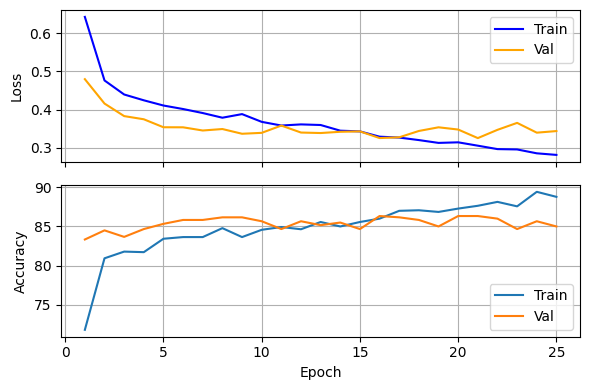

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(log_file)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4))

ax1.plot(df['epoch'], df['train_loss'], label='Train', color='blue')
ax1.plot(df['epoch'], df['val_loss'], label='Val', color='orange')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(df['epoch'], df['train_acc'], label='Train')
ax2.plot(df['epoch'], df['val_acc'], label='Val')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()